# Week 3: Python & Data Wrangling
**Assignment:** Clean a messy dataset in Pandas — handle missing values, filter rows, create new columns.

**Dataset:** `data.csv` (daily workout log, Dec 2020) — columns: `Duration` (min), `Date`, `Pulse`, `Maxpulse`, `Calories`.

## 1. Import libraries & load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raw = pd.read_csv('data.csv')
df = raw.copy()   # keep the original untouched
raw

,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0
5,60,'2020/12/06',102,127,300.0
6,60,'2020/12/07',110,136,374.0
7,450,'2020/12/08',104,134,253.3
8,30,'2020/12/09',109,133,195.1
9,60,'2020/12/10',98,124,269.0


## 2. Inspect the data (find the mess)

In [2]:
print('Shape:', df.shape)
print()
df.info()

Shape: (32, 5)

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     str    
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), str(1)
memory usage: 1.4 KB


In [3]:
print('Missing values per column:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df.describe()

Missing values per column:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Duplicate rows: 1


,Duration,Pulse,Maxpulse,Calories
count,32.000000,32.000000,32.000000,30.000000
mean,68.437500,103.500000,128.500000,304.680000
std,70.039591,7.832933,12.998759,66.003779
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.700000
50%,60.000000,102.500000,127.500000,291.200000
75%,60.000000,106.500000,132.250000,343.975000
max,450.000000,130.000000,175.000000,479.000000


**Problems found:**

| # | Problem | Where |
|---|---------|-------|
| 1 | Dates stored as text with extra quote characters (`'2020/12/01'`) | `Date` column |
| 2 | One date in a different format (`20201226`) | row 26 |
| 3 | One missing date | row 22 |
| 4 | One duplicate row (2020/12/12) | rows 11 & 12 |
| 5 | Outlier: `Duration = 450` (all other values are 30–60) | row 7 |
| 6 | Wrong values: `Pulse` (130) greater than `Maxpulse` (101) — impossible | row 23 |
| 7 | 2 missing `Calories` values | rows 18 & 28 |

(Row numbers are 0-based index positions in the raw `data.csv`.)

## 3. Clean the `Date` column

Remove the stray quotes, then convert to a proper `datetime`. The `20201226` entry has no separators, so each format is parsed separately.

In [4]:
# 3a. strip the quote characters
df['Date'] = df['Date'].str.replace("'", '', regex=False)

# 3b. parse both formats ('2020/12/01' and '20201226')
d1 = pd.to_datetime(df['Date'], format='%Y/%m/%d', errors='coerce')
d2 = pd.to_datetime(df['Date'], format='%Y%m%d', errors='coerce')
df['Date'] = d1.fillna(d2)

df[['Date']].iloc[18:30]

,Date
18,2020-12-18
19,2020-12-19
20,2020-12-20
21,2020-12-21
22,NaT
23,2020-12-23
24,2020-12-24
25,2020-12-25
26,2020-12-26
27,2020-12-27


## 4. Remove duplicate rows

In [5]:
print('Duplicates before:', df.duplicated().sum())
print(df[df.duplicated(keep=False)])
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicates after :', df.duplicated().sum())
print('Shape now:', df.shape)

Duplicates before: 1
    Duration       Date  Pulse  Maxpulse  Calories
11        60 2020-12-12    100       120     250.7
12        60 2020-12-12    100       120     250.7
Duplicates after : 0
Shape now: (31, 5)


## 5. Fix wrong values (outlier & swapped values)

### 5a. Duration outlier (450)
Every other workout is 30, 45 or 60 minutes. 450 min (7.5 hours) with only 253 calories is not realistic — it is a typing error for **45**.

In [6]:
print(df[df['Duration'] > 100])
df.loc[df['Duration'] == 450, 'Duration'] = 45
print('Max Duration now:', df['Duration'].max())

   Duration       Date  Pulse  Maxpulse  Calories
7       450 2020-12-08    104       134     253.3
Max Duration now: 60


### 5b. `Pulse` > `Maxpulse`
Average pulse can never be higher than the maximum pulse. For 23 Dec the two values are swapped (130 / 101), so they are swapped back.

In [7]:
bad = df['Pulse'] > df['Maxpulse']
print(df[bad])
df.loc[bad, ['Pulse', 'Maxpulse']] = df.loc[bad, ['Maxpulse', 'Pulse']].values
print('Rows with Pulse > Maxpulse now:', (df['Pulse'] > df['Maxpulse']).sum())

    Duration       Date  Pulse  Maxpulse  Calories
22        60 2020-12-23    130       101     300.0
Rows with Pulse > Maxpulse now: 0


## 6. Handle missing values

### 6a. Missing `Date`
The log is **one workout per day** from 1 Dec to 31 Dec. The missing date sits between 21 Dec and 23 Dec, so it can only be **22 Dec 2020**.

In [8]:
print(df[df['Date'].isna()])
idx = df.index[df['Date'].isna()][0]
before, after = df.loc[idx-1, 'Date'], df.loc[idx+1, 'Date']
print('Row before:', before.date(), '| Row after:', after.date())

# only fill if the neighbours are exactly 2 days apart (so the gap is unambiguous)
assert (after - before).days == 2
df.loc[idx, 'Date'] = before + pd.Timedelta(days=1)
print('Filled with:', df.loc[idx, 'Date'].date())

    Duration Date  Pulse  Maxpulse  Calories
21        45  NaT    100       119     282.0
Row before: 2020-12-21 | Row after: 2020-12-23
Filled with: 2020-12-22


### 6b. Missing `Calories`
Calories depend mainly on how long the workout was, so the missing values are filled with the **median Calories of workouts with the same Duration** (median is used because it is not affected by outliers). This is done *after* fixing the Duration outlier so the medians are correct.

In [9]:
print(df[df['Calories'].isna()])
df['Calories'] = df['Calories'].fillna(df.groupby('Duration')['Calories'].transform('median'))
print('\nMissing Calories now:', df['Calories'].isna().sum())
df[df['Date'].isin(pd.to_datetime(['2020-12-18', '2020-12-28']))]

    Duration       Date  Pulse  Maxpulse  Calories
17        45 2020-12-18     90       112       NaN
27        60 2020-12-28    103       132       NaN

Missing Calories now: 0


,Duration,Date,Pulse,Maxpulse,Calories
17,45,2020-12-18,90,112,267.65
27,60,2020-12-28,103,132,311.50


### Check: dataset is fully clean

In [10]:
print(df.isna().sum())
print('Duplicates:', df.duplicated().sum())
print('Dates unique & daily:', df['Date'].is_unique, '|', df['Date'].min().date(), 'to', df['Date'].max().date(), '|', len(df), 'rows')
df.dtypes

Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64
Duplicates: 0
Dates unique & daily: True | 2020-12-01 to 2020-12-31 | 31 rows


Duration             int64
Date        datetime64[us]
Pulse                int64
Maxpulse             int64
Calories           float64
dtype: object

## 7. Filter rows

**Filter 1:** Workouts of 60 minutes with more than 350 calories burned.

In [11]:
f1 = df[(df['Duration'] == 60) & (df['Calories'] > 350)]
print(len(f1), 'rows')
f1

6 rows


,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
6,60,2020-12-07,110,136,374.0
13,60,2020-12-14,104,132,379.3
20,60,2020-12-21,108,131,364.2
29,60,2020-12-30,102,129,380.3


**Filter 2:** Workouts where the maximum pulse crossed 140.

In [12]:
f2 = df[df['Maxpulse'] > 140]
print(len(f2), 'rows')
f2

4 rows


,Duration,Date,Pulse,Maxpulse,Calories
1,60,2020-12-02,117,145,479.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0
10,60,2020-12-11,103,147,329.3


**Filter 3:** Workouts in the second half of the month (16 Dec onward).

In [13]:
f3 = df[df['Date'] >= '2020-12-16']
print(len(f3), 'rows')
f3.head()

16 rows


,Duration,Date,Pulse,Maxpulse,Calories
15,60,2020-12-16,98,120,215.20
16,60,2020-12-17,100,120,300.00
17,45,2020-12-18,90,112,267.65
18,60,2020-12-19,103,123,323.00
19,45,2020-12-20,97,125,243.00


## 8. Create new columns

In [14]:
df['Weekday']          = df['Date'].dt.day_name()
df['Week']             = df['Date'].dt.isocalendar().week.astype(int)
df['Calories_per_min'] = (df['Calories'] / df['Duration']).round(2)
df['Pulse_Ratio']      = (df['Pulse'] / df['Maxpulse']).round(2)

df['Intensity'] = pd.cut(df['Calories_per_min'],
                         bins=[0, 5, 6.5, np.inf],
                         labels=['Low', 'Medium', 'High'])
df['Is_Weekend'] = df['Weekday'].isin(['Saturday', 'Sunday'])
df.head(10)

,Duration,Date,Pulse,Maxpulse,Calories,Weekday,Week,Calories_per_min,Pulse_Ratio,Intensity,Is_Weekend
0,60,2020-12-01,110,130,409.1,Tuesday,49,6.82,0.85,High,False
1,60,2020-12-02,117,145,479.0,Wednesday,49,7.98,0.81,High,False
2,60,2020-12-03,103,135,340.0,Thursday,49,5.67,0.76,Medium,False
3,45,2020-12-04,109,175,282.4,Friday,49,6.28,0.62,Medium,False
4,45,2020-12-05,117,148,406.0,Saturday,49,9.02,0.79,High,True
5,60,2020-12-06,102,127,300.0,Sunday,49,5.00,0.80,Low,True
6,60,2020-12-07,110,136,374.0,Monday,50,6.23,0.81,Medium,False
7,45,2020-12-08,104,134,253.3,Tuesday,50,5.63,0.78,Medium,False
8,30,2020-12-09,109,133,195.1,Wednesday,50,6.50,0.82,Medium,False
9,60,2020-12-10,98,124,269.0,Thursday,50,4.48,0.79,Low,False


`Intensity` is based on calories burned per minute: **Low** ≤ 5, **Medium** 5–6.5, **High** > 6.5.

## 9. Quick analysis

In [15]:
print(df['Intensity'].value_counts().sort_index())
print()
print(df.groupby('Duration')[['Calories', 'Pulse', 'Maxpulse']].mean().round(1))
print()
print(df.groupby('Is_Weekend')['Calories'].mean().round(1))

Intensity
Low       11
Medium    17
High       3
Name: count, dtype: int64

          Calories  Pulse  Maxpulse
Duration                           
30           195.1  109.0     133.0
45           282.9  103.1     135.0
60           317.1  102.3     128.0

Is_Weekend
False    309.1
True     294.9
Name: Calories, dtype: float64


## 10. Visualization (Matplotlib & Seaborn)

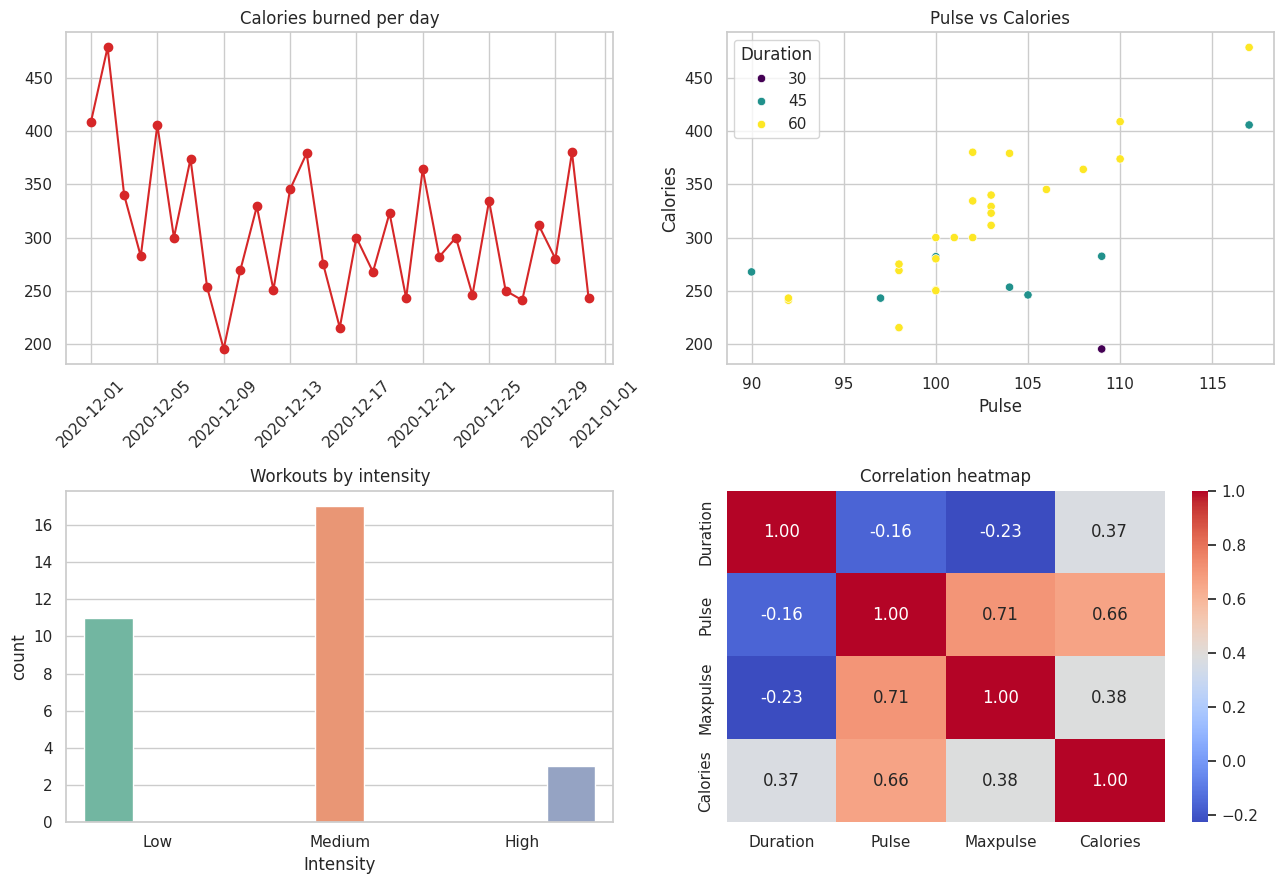

In [16]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].plot(df['Date'], df['Calories'], marker='o', color='tab:red')
ax[0, 0].set_title('Calories burned per day'); ax[0, 0].tick_params(axis='x', rotation=45)

sns.scatterplot(data=df, x='Pulse', y='Calories', hue='Duration', palette='viridis', ax=ax[0, 1])
ax[0, 1].set_title('Pulse vs Calories')

sns.countplot(data=df, x='Intensity', hue='Intensity', palette='Set2', legend=False, ax=ax[1, 0])
ax[1, 0].set_title('Workouts by intensity')

sns.heatmap(df[['Duration', 'Pulse', 'Maxpulse', 'Calories']].corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax[1, 1])
ax[1, 1].set_title('Correlation heatmap')

plt.tight_layout()
plt.savefig('plots.png', dpi=150)
plt.show()

## 11. Save the cleaned data

In [17]:
df.to_csv('cleaned_data.csv', index=False)
pd.read_csv('cleaned_data.csv').head()

,Duration,Date,Pulse,Maxpulse,Calories,Weekday,Week,Calories_per_min,Pulse_Ratio,Intensity,Is_Weekend
0,60,2020-12-01,110,130,409.1,Tuesday,49,6.82,0.85,High,False
1,60,2020-12-02,117,145,479.0,Wednesday,49,7.98,0.81,High,False
2,60,2020-12-03,103,135,340.0,Thursday,49,5.67,0.76,Medium,False
3,45,2020-12-04,109,175,282.4,Friday,49,6.28,0.62,Medium,False
4,45,2020-12-05,117,148,406.0,Saturday,49,9.02,0.79,High,True


## Summary of cleaning steps
1. Stripped quotes and unified date formats → proper `datetime`
2. Removed 1 duplicate row (12 Dec)
3. Filled missing date (22 Dec) from the daily sequence
4. Corrected Duration outlier 450 → 45
5. Swapped Pulse/Maxpulse where Pulse > Maxpulse (23 Dec)
6. Filled 2 missing Calories with median of same-Duration workouts
7. Filtered rows (3 examples) and created new columns: `Weekday`, `Week`, `Calories_per_min`, `Pulse_Ratio`, `Intensity`, `Is_Weekend`
8. Visualised with Matplotlib & Seaborn and saved `cleaned_data.csv`